# Ratio of reflected to incident GSN amplitudes

Besides GeneralizedSasakiNakamura (Julia 1.12 or later), this notebook uses Plots and LaTeXStrings; add them to your environment first with `using Pkg; Pkg.add(["Plots", "LaTeXStrings"])`.

For each frequency we solve for the IN GSN function with `GSN_radial(s, l, m, a, omega, IN; method = "ISEM")`. At infinity $X^{\rm in} \to A^{{\rm GSN},{\rm inc}} e^{-i\omega r_*} + A^{{\rm GSN},{\rm ref}} e^{+i\omega r_*}$, and we plot $|A^{{\rm GSN},{\rm ref}}/A^{{\rm GSN},{\rm inc}}|$ (`reflection_amplitude/incidence_amplitude`). This ratio depends on how the GSN function is defined and is not the energy reflectivity of the black hole. At $a = 0$ the curves for $s$ and $-s$ coincide, so the first plot shows three distinct curves. At $a = 0.7$ they differ: the ratio rises above 1 at low frequency for $s = 1, 2$ and stays below 1 for $s = -1, -2$. This does not mark superradiance, which occurs for every $s$ at $\omega < m\Omega_H \approx 0.41$.


In [1]:
using GeneralizedSasakiNakamura
using Plots, LaTeXStrings


In [2]:
function reflectivity_curve(s, l, m, a, omegas)
    return [begin
        Xin = GSN_radial(s, l, m, a, omega, IN; method = "ISEM")
        Xin.reflection_amplitude / Xin.incidence_amplitude
    end for omega in omegas]
end

s_values = -2:2
l = 2
m = 2
omegas = collect(range(0.02, 2.0; length = 100))

# Warm up once before the frequency sweeps.
GSN_radial(-2, l, m, 0.0, first(omegas), IN; method = "ISEM")


GSNRadialFunction(
    mode = Mode(s = -2, l = 2, m = 2, a = 0.0, omega = 0.02, lambda = 4.0),
    boundary_condition = IN,
    rsin = missing,
    rsout = missing,
    rsmp = 24.394449154672444,
    horizon_expansion_order = 80,
    infinity_expansion_order = 24,
    transmission_amplitude = 1.0 + 0.0im,
    incidence_amplitude = 20215.60919643624 - 107205.8708249867im,
    reflection_amplitude = 10915.430488063836 + 108547.7911833632im,
    normalization_convention = UNIT_GSN_TRANS,
    method = ISEM
)

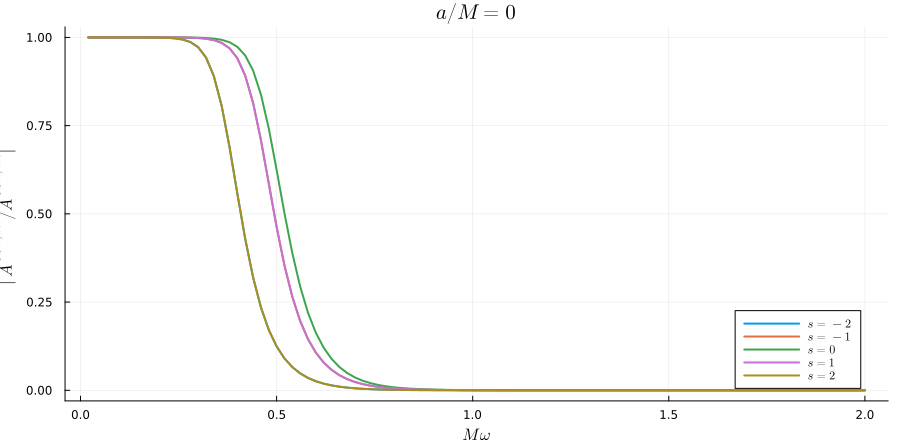

In [3]:
nonrotating = Dict(s => reflectivity_curve(s, l, m, 0.0, omegas) for s in s_values)

plot(omegas, abs.(nonrotating[-2]); linewidth = 2, label = L"s = -2")
for s in -1:2
    plot!(omegas, abs.(nonrotating[s]); linewidth = 2, label = latexstring("s = $s"))
end
plot!(; xlabel = L"M\omega", ylabel = L"|A^{\mathrm{GSN,ref}}/A^{\mathrm{GSN,inc}}|",
    title = L"a/M=0", legend = :bottomright, size = (900, 440))


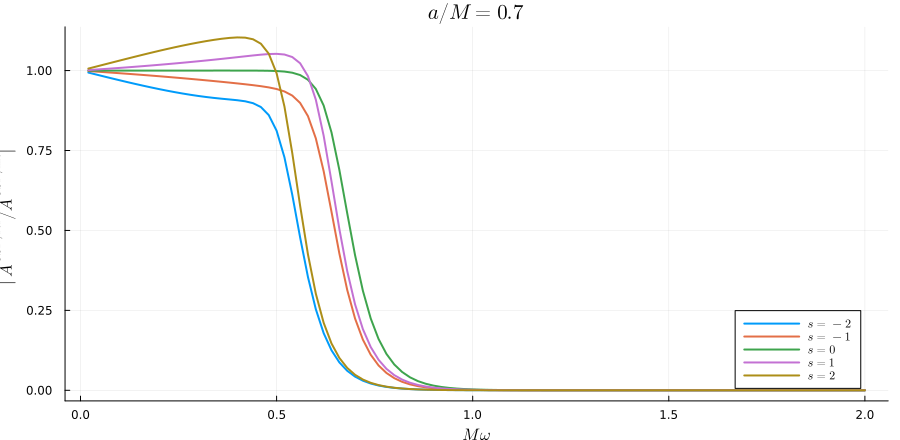

In [4]:
rotating = Dict(s => reflectivity_curve(s, l, m, 0.7, omegas) for s in s_values)

plot(omegas, abs.(rotating[-2]); linewidth = 2, label = L"s = -2")
for s in -1:2
    plot!(omegas, abs.(rotating[s]); linewidth = 2, label = latexstring("s = $s"))
end
plot!(; xlabel = L"M\omega", ylabel = L"|A^{\mathrm{GSN,ref}}/A^{\mathrm{GSN,inc}}|",
    title = L"a/M=0.7", legend = :bottomright, size = (900, 440))
